In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_recall_curve, confusion_matrix

# ---------------- CONFIG ----------------
COUNTRY = "Zambia"                 # "India" or "Zambia"
SPIKE_TARGET = "spike_next"       # "spike_next" (10%) or "spike_next_severe" (15%)
TRAIN_FRAC = 0.6
MIN_TRAIN = 48
SEED = 42
# ----------------------------------------

tag = f"{COUNTRY.lower()}_{SPIKE_TARGET}"
BASELINES = {"Naive", "SeasonalNaive", "Persistence"}

data = pd.read_csv(f"features_{COUNTRY.lower()}.csv", parse_dates=["date"])
data = data.sort_values(["commodity", "date"]).reset_index(drop=True)
results = pd.read_csv(f"predictions_{tag}.csv", parse_dates=["date"])
reg_table = pd.read_csv(f"results_regression_{tag}.csv")
cls_table = pd.read_csv(f"results_classification_{tag}.csv")

ID_COLS = ["date", "country", "commodity", "currency", "n_markets", "was_filled"]
TARGET_COLS = ["next_price", "next_mom", "spike_next", "spike_next_severe"]
FEATURES = [c for c in data.columns if c not in ID_COLS + TARGET_COLS + ["price"]]
coms = results["commodity"].unique()

In [11]:
naive = (reg_table[reg_table["model"] == "Naive"]
         .set_index("commodity")[["MAE", "RMSE"]]
         .rename(columns={"MAE": "MAE_naive", "RMSE": "RMSE_naive"}))

skill = reg_table.join(naive, on="commodity")
skill["MAE_gain_%"] = ((skill["MAE_naive"] - skill["MAE"]) / skill["MAE_naive"] * 100).round(1)
skill["RMSE_gain_%"] = ((skill["RMSE_naive"] - skill["RMSE"]) / skill["RMSE_naive"] * 100).round(1)
print("Price forecast: gain over Naive (positive = better)")
display(skill[skill["model"] != "Naive"]
        [["commodity", "model", "MAE", "MAE_gain_%", "RMSE_gain_%", "MAPE_%"]]
        .sort_values(["commodity", "MAE_gain_%"], ascending=[True, False]))

cls_table["lift_vs_base"] = (cls_table["pr_auc"] / cls_table["base_rate"]).round(2)
print("Spike detection: lift = PR-AUC / base rate (1.0 = no better than chance)")
display(cls_table[~cls_table["model"].isin({"Naive"})]
        .sort_values(["commodity", "pr_auc"], ascending=[True, False])
        [["commodity", "model", "n_spikes", "base_rate", "pr_auc", "lift_vs_base", "precision", "recall", "f1"]])

Price forecast: gain over Naive (positive = better)


,commodity,model,MAE,MAE_gain_%,RMSE_gain_%,MAPE_%
0,Maize (white),RandomForest,0.169,8.2,13.7,8.26
1,Maize (white),Ridge,0.179,2.7,9.7,8.79
2,Maize (white),XGBoost,0.180,2.2,14.4,8.95
4,Maize (white),SARIMA,0.201,-9.2,-2.9,9.71
5,Maize (white),SeasonalNaive,0.592,-221.7,-188.8,25.01


Spike detection: lift = PR-AUC / base rate (1.0 = no better than chance)


,commodity,model,n_spikes,base_rate,pr_auc,lift_vs_base,precision,recall,f1
0,Maize (white),RandomForest (clf),11,0.139,0.289,2.08,0.000,0.000,0.000
1,Maize (white),XGBoost (clf),11,0.139,0.244,1.76,0.333,0.091,0.143
2,Maize (white),SARIMA,11,0.139,0.226,1.63,0.333,0.091,0.143
3,Maize (white),RandomForest,11,0.139,0.210,1.51,0.000,0.000,0.000
4,Maize (white),Ridge,11,0.139,0.196,1.41,0.111,0.091,0.100
5,Maize (white),SeasonalNaive,11,0.139,0.195,1.40,0.214,0.273,0.240
6,Maize (white),XGBoost,11,0.139,0.174,1.25,0.000,0.000,0.000
7,Maize (white),Logistic (clf),11,0.139,0.162,1.17,0.158,0.545,0.245
9,Maize (white),Persistence,11,0.139,0.135,0.97,0.091,0.091,0.091


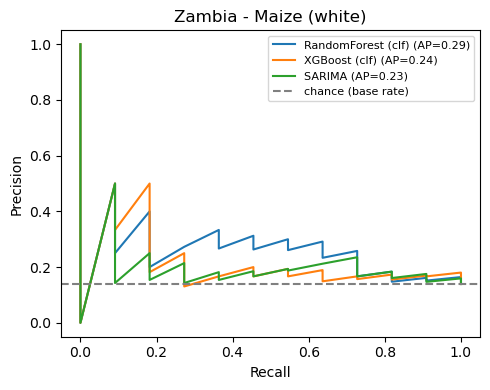

In [12]:
fig, axes = plt.subplots(1, len(coms), figsize=(5 * len(coms), 4), squeeze=False)
for ax, com in zip(axes[0], coms):
    ct = (cls_table[(cls_table["commodity"] == com) & (cls_table["model"] != "Naive")]
          .sort_values("pr_auc", ascending=False).head(3))
    sub = results[results["commodity"] == com]
    for m, ap in zip(ct["model"], ct["pr_auc"]):
        s = sub[sub["model"] == m]
        p, r, _ = precision_recall_curve(s["y_true_spike"], s["score"])
        ax.plot(r, p, label=f"{m} (AP={ap:.2f})")
    ax.axhline(sub["y_true_spike"].mean(), ls="--", c="grey", label="chance (base rate)")
    ax.set_title(f"{COUNTRY} - {com}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

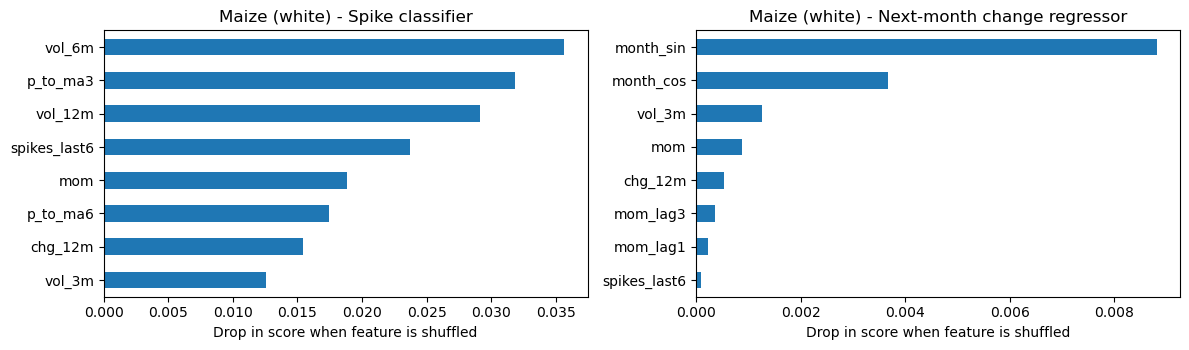

In [13]:
def perm_importance(g, kind):
    g = g.sort_values("date").reset_index(drop=True)
    N = len(g)
    s = max(int(N * TRAIN_FRAC), MIN_TRAIN)
    Xtr, Xte = g.loc[: s - 1, FEATURES], g.loc[s:, FEATURES]
    if kind == "clf":
        ytr, yte = g.loc[: s - 1, SPIKE_TARGET], g.loc[s:, SPIKE_TARGET]
        if yte.sum() == 0:
            return None
        m = RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                   class_weight="balanced_subsample",
                                   random_state=SEED, n_jobs=-1)
        scoring = "average_precision"
    else:
        ytr, yte = g.loc[: s - 1, "next_mom"], g.loc[s:, "next_mom"]
        m = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                  random_state=SEED, n_jobs=-1)
        scoring = "neg_mean_absolute_error"
    m.fit(Xtr, ytr)
    pi = permutation_importance(m, Xte, yte, scoring=scoring,
                                n_repeats=30, random_state=SEED, n_jobs=-1)
    return pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(len(coms), 2, figsize=(12, 3.6 * len(coms)), squeeze=False)
for row, com in zip(axes, coms):
    g = data[data["commodity"] == com]
    for ax, kind, title in zip(row, ["clf", "reg"],
                               ["Spike classifier", "Next-month change regressor"]):
        imp = perm_importance(g, kind)
        if imp is None:
            ax.set_title(f"{com} - {title}: no spikes in test")
            continue
        imp.head(8)[::-1].plot.barh(ax=ax)
        ax.set_title(f"{com} - {title}")
        ax.set_xlabel("Drop in score when feature is shuffled")
plt.tight_layout()
plt.show()


=== Zambia - Maize (white) | best model: RandomForest (clf) ===
caught=0  missed=11  false alarms=1  correct quiet months=67
Calendar months of true spikes: [3, 3, 6, 7, 8, 9, 9, 11, 11, 12, 12]


,target_month,score,flagged
639,2014-07-01,0.305926,0
647,2015-03-01,0.333361,0
655,2015-11-01,0.110496,0
665,2016-09-01,0.259712,0
668,2016-12-01,0.338397,0
674,2017-06-01,0.401639,0
676,2017-08-01,0.241178,0
701,2019-09-01,0.126508,0
703,2019-11-01,0.183697,0
704,2019-12-01,0.444938,0


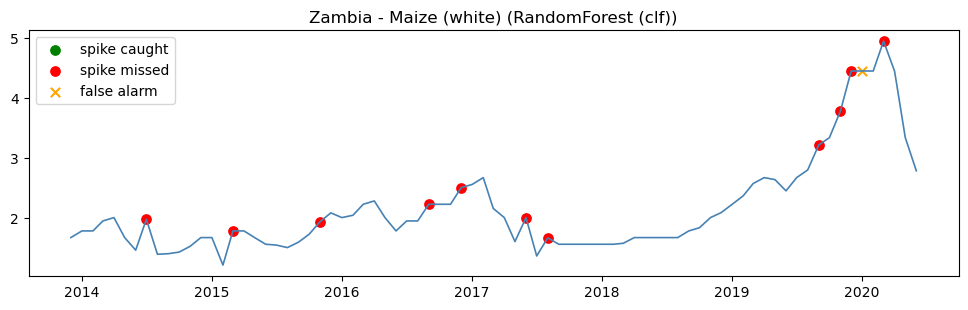

In [17]:
for com in coms:
    best = (cls_table[(cls_table["commodity"] == com) & (~cls_table["model"].isin(BASELINES))]
            .sort_values("pr_auc", ascending=False).iloc[0]["model"])
    s = results[(results["commodity"] == com) & (results["model"] == best)].copy()
    s["target_month"] = s["date"] + pd.DateOffset(months=1)

    tn, fp, fn, tp = confusion_matrix(s["y_true_spike"], s["y_pred_spike"], labels=[0, 1]).ravel()
    print(f"\n=== {COUNTRY} - {com} | best model: {best} ===")
    print(f"caught={tp}  missed={fn}  false alarms={fp}  correct quiet months={tn}")

    spikes = s[s["y_true_spike"] == 1][["target_month", "score", "y_pred_spike"]]
    print("Calendar months of true spikes:", sorted(spikes["target_month"].dt.month.tolist()))
    display(spikes.rename(columns={"y_pred_spike": "flagged"}))

    fig, ax = plt.subplots(figsize=(12, 3.2))
    ax.plot(s["target_month"], s["y_true_price"], lw=1.2, c="steelblue")
    caught = s[(s["y_true_spike"] == 1) & (s["y_pred_spike"] == 1)]
    missed = s[(s["y_true_spike"] == 1) & (s["y_pred_spike"] == 0)]
    false = s[(s["y_true_spike"] == 0) & (s["y_pred_spike"] == 1)]
    ax.scatter(caught["target_month"], caught["y_true_price"], c="green", s=45, label="spike caught")
    ax.scatter(missed["target_month"], missed["y_true_price"], c="red", s=45, label="spike missed")
    ax.scatter(false["target_month"], false["y_true_price"], c="orange", marker="x", s=45, label="false alarm")
    ax.set_title(f"{COUNTRY} - {com} ({best})")
    ax.legend(loc="upper left")
    plt.show()

In [15]:
def load_cls(t):
    return pd.read_csv(f"results_classification_{COUNTRY.lower()}_{t}.csv")

both = pd.concat([load_cls("spike_next").assign(threshold="10%"),
                  load_cls("spike_next_severe").assign(threshold="15%")])
both["lift_vs_base"] = (both["pr_auc"] / both["base_rate"]).round(2)

best_by_thr = (both[~both["model"].isin(BASELINES)]
               .sort_values("pr_auc", ascending=False)
               .groupby(["commodity", "threshold"]).head(1)
               .sort_values(["commodity", "threshold"])
               [["commodity", "threshold", "model", "n_spikes", "base_rate",
                 "pr_auc", "lift_vs_base", "precision", "recall"]])
best_by_thr

,commodity,threshold,model,n_spikes,base_rate,pr_auc,lift_vs_base,precision,recall
0,Maize (white),10%,RandomForest (clf),11,0.139,0.289,2.08,0.000,0.0
0,Maize (white),15%,Logistic (clf),5,0.063,0.277,4.40,0.059,0.2


In [16]:
skill.to_csv(f"summary_gain_over_naive_{tag}.csv", index=False)
cls_table.to_csv(f"summary_spike_detection_{tag}.csv", index=False)